# Figure 4A

In [1]:
from riskhistory.format import rcParams
from riskhistory.setup_pupilbetas.utils_prf import get_prf
from riskhistory.setup_pupilbetas.utils_create_regressors import (
    create_timings_matrix,
    convolve_with_prf,
)
import numpy as np
import matplotlib.pyplot as plt

### Helper functions

In [2]:
def _draw_big_paren(ax, direction=1, lw=3, color="black", curvature=0.35,
                    y_bottom=0.03, y_top=0.97, x_center=0.5):
    """direction=+1 draws '(' (bulges right), -1 draws ')' (bulges left)."""
    y = np.linspace(y_bottom, y_top, 200)
    x = x_center + direction * curvature * np.sin(np.pi * (y - y_bottom) / (y_top - y_bottom))
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")


def _draw_big_bracket(ax, direction=1, lw=3, color="black", tick=0.2,
                      y_bottom=0.03, y_top=0.97, x=0.6):
    """direction=+1 draws '[' (ticks point right), -1 draws ']' (ticks point left)."""
    ax.plot([x, x], [y_bottom, y_top], color=color, lw=lw, clip_on=False)
    ax.plot([x, x + direction * tick], [y_top, y_top], color=color, lw=lw, clip_on=False)
    ax.plot([x, x + direction * tick], [y_bottom, y_bottom], color=color, lw=lw, clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")


def plot_pupil_glm_schematic(fig, regressors, time_vector, t_max, prf, prf_time,
                             prf_max_secs, predicted_signal, beta_labels,
                             regressor_color="black"):
    """Draws the pupil-GLM conceptual schematic into `fig`: a stack of
    regressor timecourses, convolved with the canonical PRF (*), multiplied
    by a beta vector ([...]), summed (=) into the predicted pupil signal."""
    row_names = list(regressors.keys())

    gs = fig.add_gridspec(
        nrows=4, ncols=11,
        width_ratios=[0.1, 1.0, 4, 0.4, 3, 0.25, 0.2, 1.4, 0.2, 0.4, 4],
        wspace=0.08, hspace=0.4, left=0.02, right=0.98,
    )

    paren_left_ax = fig.add_subplot(gs[:, 0])
    spacer_ax = fig.add_subplot(gs[:, 1]); spacer_ax.axis("off")
    row_axes = [fig.add_subplot(gs[i, 2]) for i in range(len(row_names))]
    for ax in row_axes[1:]:
        ax.sharex(row_axes[0])

    symbol1_ax = fig.add_subplot(gs[:, 3]); symbol1_ax.axis("off")
    prf_ax = fig.add_subplot(gs[:, 4])
    paren_right_ax = fig.add_subplot(gs[:, 5])
    bracket_left_ax = fig.add_subplot(gs[:, 6])
    beta_vec_ax = fig.add_subplot(gs[:, 7])
    bracket_right_ax = fig.add_subplot(gs[:, 8])
    symbol2_ax = fig.add_subplot(gs[:, 9]); symbol2_ax.axis("off")
    signal_ax = fig.add_subplot(gs[:, 10])

    for i, name in enumerate(row_names):
        ax = row_axes[i]
        reg = regressors[name]

        if name in ("Stimuli\nOnset", "Button\nPresses"):
            event_times = [0.5, 5.0] if name == "Stimuli\nOnset" else [2.0, 6.0]
            ax.axhline(0, color=regressor_color, linewidth=1.5, zorder=1)
            ax.vlines(event_times, ymin=0, ymax=1, color=regressor_color, linewidth=3, zorder=2)
            ax.set_ylim(-0.15, 1.3)
            ax.text(0.97, 0.5, "...", transform=ax.transAxes, ha="right", va="center",
                   fontsize=24, fontweight="bold")
        else:
            ax.fill_between(time_vector, reg, step="post", color=regressor_color, alpha=0.6)
            ax.plot(time_vector, reg, drawstyle="steps-post", color=regressor_color, linewidth=1.5)
            ax.set_ylim(-0.15 * reg.max(), reg.max() * 1.5)

        ax.set_xlim(0, t_max)
        ax.set_xticks(np.arange(0, t_max + 1, 1))
        ax.set_yticks([])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        label_color = "black" if "Decision" in name else "grey"
        ax.text(-0.05, 0.5, name, transform=ax.transAxes, ha="right", va="center",
               fontsize=20, color=label_color)

        if i < len(row_names) - 1:
            ax.tick_params(labelbottom=False)
            ax.spines["bottom"].set_visible(False)
        else:
            ax.set_xlabel("Time (s)")

    row_axes[0].text(0.5, 1.35, "Pupil Regressors", transform=row_axes[0].transAxes,
                     ha="center", va="bottom", fontweight="bold", fontsize=24)

    symbol1_ax.text(0.5, 0.5, "*", ha="center", va="center", fontsize=48,
                   transform=symbol1_ax.transAxes)

    prf_ax.plot(prf_time, prf, color="black", linewidth=3)
    prf_ax.fill_between(prf_time, prf, color="gray", alpha=0.3)
    prf_ax.set_xlim(0, prf_max_secs)
    prf_ax.set_xlabel("Time since event (s)")
    prf_ax.set_yticks([])
    prf_ax.spines["top"].set_visible(False)
    prf_ax.spines["right"].set_visible(False)
    prf_ax.spines["left"].set_visible(False)
    prf_ax.text(0.5, 1.02, "Canonical Pupil\nResponse Function",
               transform=prf_ax.transAxes, ha="center", va="bottom",
               fontstyle="italic", fontsize=24)

    # Big "( ... )" spanning from the left of the regressor stack to the
    # right of the PRF panel -- groups "regressors * PRF" as a single term
    # (the convolved design matrix).
    _draw_big_paren(paren_left_ax, direction=-1, x_center=1)
    _draw_big_paren(paren_right_ax, direction=1, x_center=0.8)

    # Beta column vector, wrapped in a big "[ ... ]", multiplying the
    # parenthesized convolved-design term.
    _draw_big_bracket(bracket_left_ax, direction=1)
    _draw_big_bracket(bracket_right_ax, direction=-1)
    beta_vec_ax.set_xlim(0, 1)
    beta_vec_ax.set_ylim(0, 1)
    beta_vec_ax.axis("off")
    n_beta = len(beta_labels)
    for i, lbl in enumerate(beta_labels):
        y = 1 - (i + 0.5) / n_beta
        beta_vec_ax.text(0.5, y, lbl, ha="center", va="center", fontsize=20)

    symbol2_ax.text(0.5, 0.5, "=", ha="center", va="center", fontsize=48,
                   transform=symbol2_ax.transAxes)

    signal_ax.plot(time_vector, predicted_signal, color="black", linewidth=3)
    signal_ax.set_xlim(0, t_max)
    signal_ax.set_xlabel("Time (s)")
    signal_ax.set_yticks([])
    signal_ax.spines["top"].set_visible(False)
    signal_ax.spines["right"].set_visible(False)
    signal_ax.spines["left"].set_visible(False)
    signal_ax.text(0.5, 1.02, "Predicted Pupil Signal", transform=signal_ax.transAxes,
                  ha="center", va="bottom", fontweight="bold", fontsize=24)

### Build schematic data
Same construction as `pupilglm_schematic.ipynb`: 4 regressors built with the real `create_timings_matrix`, convolved with the real PRF, summed with different weights into a simulated "predicted" pupil signal.

In [3]:
FS = 25          # samples/sec, matches the real pipeline's default
T_MAX = 8.0      # seconds shown for the regressor rows and predicted signal
PRF_MAX_SECS = 4.0

time_vector = np.arange(0, T_MAX, 1 / FS)

onset_matrix, _ = create_timings_matrix(
    trial_timings={1: 0.5, 2: 5.0}, time_vector=time_vector, trial_durations=None,
    option="all", sub=None, run=None, dataset=None, regressor_name="onset",
)
button_matrix, _ = create_timings_matrix(
    trial_timings={1: 2.0, 2: 6.0}, time_vector=time_vector, trial_durations=None,
    option="all", sub=None, run=None, dataset=None, regressor_name="button",
)
decision_matrix, _ = create_timings_matrix(
    trial_timings={1: 0.5, 2: 5.0}, time_vector=time_vector,
    trial_durations={1: 1.5, 2: 1.0}, option="ls-a",
    sub=None, run=None, dataset=None, regressor_name="decision",
)

SCHEMATIC_REGRESSORS = {
    "Stimuli\nOnset":    onset_matrix[:, 0],
    "Button\nPresses":   button_matrix[:, 0],
    "Decision\nTrial 1": decision_matrix[:, 0],
    "Decision\nTrial 2": decision_matrix[:, 1],
}

prf = get_prf(max_secs=PRF_MAX_SECS, width=10.1, time_to_peak=930, sampling_rate=FS)
prf_time = np.arange(0, PRF_MAX_SECS, 1 / FS)[: len(prf)]

schematic_convolved = {
    name: convolve_with_prf(reg.reshape(-1, 1), prf, normalize=True)[:, 0]
    for name, reg in SCHEMATIC_REGRESSORS.items()
}

SCHEMATIC_BETAS = {
    "Stimuli\nOnset": 0.3,
    "Button\nPresses": 0.25,
    "Decision\nTrial 1": 1.0,
    "Decision\nTrial 2": 0.8,
}
schematic_predicted = sum(
    SCHEMATIC_BETAS[name] * schematic_convolved[name] for name in SCHEMATIC_REGRESSORS
)

BETA_VEC_LABELS = [r"$\beta_{Onset}$", r"$\beta_{Button}$",
                  r"$\mathbf{\beta_{Trial1}}$", r"$\mathbf{\beta_{Trial2}}$", r"$\vdots$"]

### Figure 4A: Pupil GLM conceptual schematic

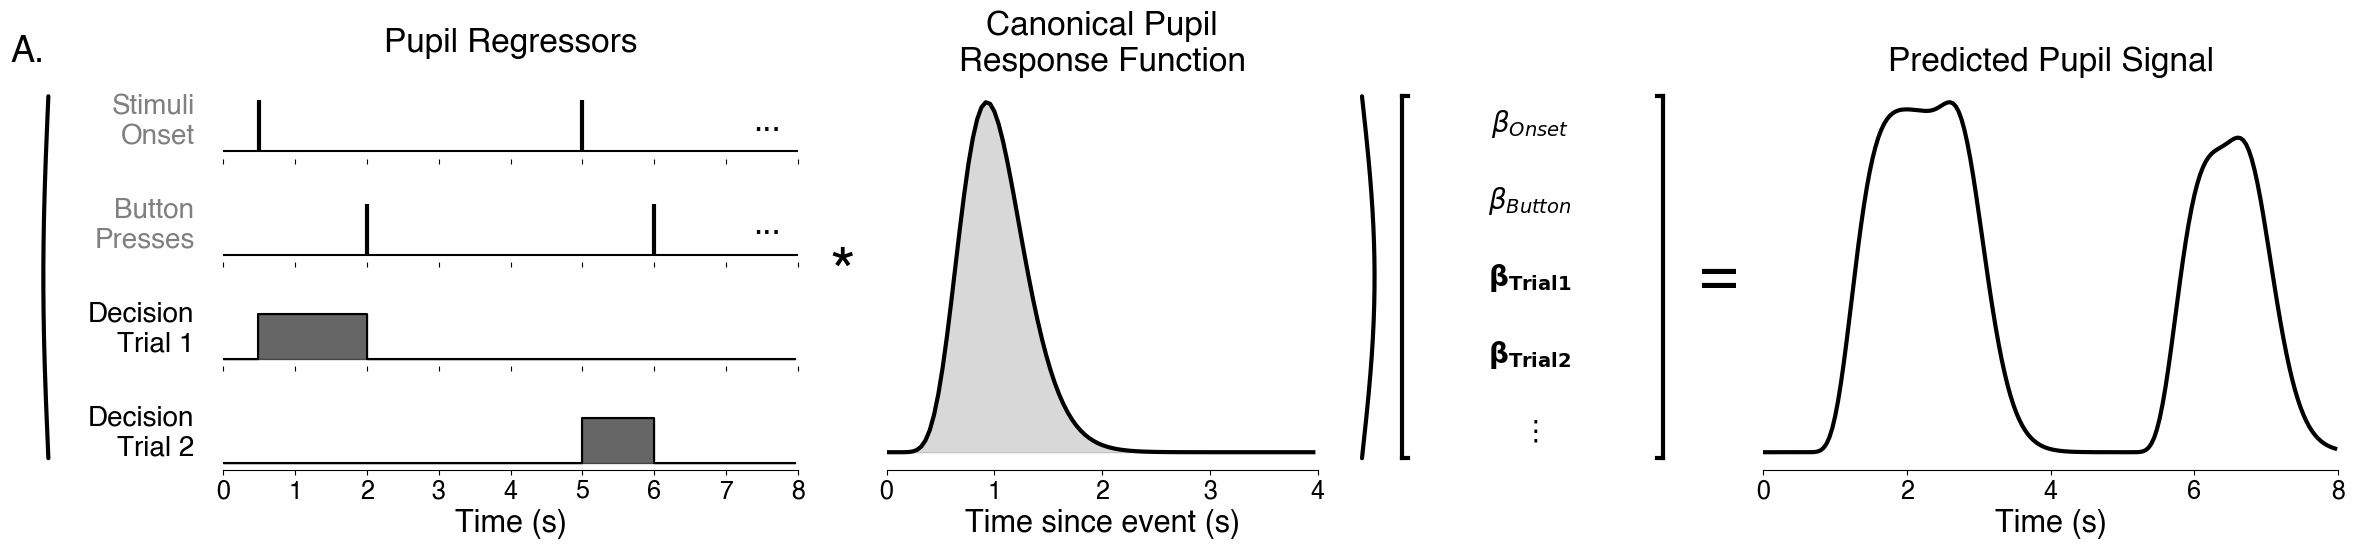

In [4]:
fig = plt.figure(figsize=(24, 5))
plot_pupil_glm_schematic(
    fig, regressors=SCHEMATIC_REGRESSORS, time_vector=time_vector, t_max=T_MAX,
    prf=prf, prf_time=prf_time, prf_max_secs=PRF_MAX_SECS,
    predicted_signal=schematic_predicted, beta_labels=BETA_VEC_LABELS,
)

fig.text(0.01, 0.98, "A.", transform=fig.transFigure,
         fontsize=26, fontweight="bold", va="top", ha="left")

fig.savefig("saved/figure4_A.svg", dpi=300, bbox_inches="tight")
plt.show()